In [ ]:
print("My OTT analytics project has started!")

# OTT Subscriber & Content Engagement Analytics

## Project Overview

This project analyses subscriber profiles and viewing-session data to explore engagement patterns and subsequent repeat viewing in a simulated OTT platform dataset.

The analysis focuses on identifying behavioural differences across engagement segments, evaluating repeat viewing over a defined follow-up period, and comparing content performance across genres and content types.

## Business Questions

1. How does early viewing engagement relate to subsequent repeat viewing?
2. Which content genres have higher average completion rates?
3. How do engagement patterns vary across acquisition channels, subscription plans, and primary devices?
4. What insights could help an OTT platform investigate opportunities to improve viewer engagement?

## Tools & Technologies

- Python
- Pandas and NumPy
- Matplotlib
- SciPy
- Jupyter Notebook / Kaggle Notebooks

## Dataset

The project uses simulated data containing 10,000 subscriber profiles and 150,000 viewing-session records. The dataset is intended for analytical practice and does not represent real customer data from an OTT company.

## Analytical Approach

1. Data inspection and quality checks
2. Subscriber-level aggregation
3. Engagement segmentation
4. Repeat-viewing analysis using a 30-day engagement window followed by a 30-day observation window
5. Content and subscriber-segment comparisons
6. Statistical testing and visualisation
7. Business interpretation and recommendations

## Important Limitation

Repeat viewing is a behavioural measure and is not equivalent to paid-subscription retention or churn. The analysis is observational and uses simulated data; findings should not be interpreted as causal effects or as evidence of real-world OTT customer behaviour.

In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/auhonabiswas/ott-analytics/README.md
/kaggle/input/datasets/auhonabiswas/ott-analytics/subscribers.csv
/kaggle/input/datasets/auhonabiswas/ott-analytics/viewing_sessions.csv


## 1. Import Libraries and Load Data

In [2]:
import pandas as pd

# Load the two datasets
subscribers = pd.read_csv(
    "/kaggle/input/datasets/auhonabiswas/ott-analytics/subscribers.csv"
)

sessions = pd.read_csv(
    "/kaggle/input/datasets/auhonabiswas/ott-analytics/viewing_sessions.csv"
)

# Check the size of each dataset
print("Subscribers dataset:", subscribers.shape)
print("Viewing sessions dataset:", sessions.shape)

Subscribers dataset: (10000, 8)
Viewing sessions dataset: (150000, 9)


In [3]:
display(subscribers.head())

,subscriber_id,join_date,age,subscription_plan,primary_device,region,preferred_language,acquisition_channel
0,SUB00001,2025-01-22,54,Standard,Mobile,West,Marathi,Paid Ads
1,SUB00002,2025-05-17,43,Mobile,Mobile,South,Bengali,Social Media
2,SUB00003,2024-08-24,29,Premium,Mobile,East,Hindi,Social Media
3,SUB00004,2025-02-06,44,Mobile,Mobile,South,Bengali,Organic
4,SUB00005,2024-08-15,18,Premium,Smart TV,South,Tamil,Social Media


In [4]:
display(sessions.head())

,session_id,subscriber_id,session_date,genre,content_type,content_language,watch_duration_mins,completion_pct,device_used
0,SES000001,SUB09296,2025-01-13,Comedy,Movie,Tamil,46,4.3,Tablet
1,SES000002,SUB01420,2025-09-01,Thriller,Movie,Hindi,64,78.8,Laptop
2,SES000003,SUB01001,2025-05-12,Documentary,Movie,Telugu,72,100.0,Smart TV
3,SES000004,SUB02389,2024-05-15,Thriller,Movie,Hindi,58,100.0,Mobile
4,SES000005,SUB00205,2025-04-20,Drama,Movie,Hindi,39,80.2,Mobile


In [ ]:
# Understand the subscriber dataset
print("SUBSCRIBER DATA")
subscribers.info()

print("\nVIEWING SESSION DATA")
sessions.info()

## 2. Data Quality Checks

In [5]:
print("Missing values in subscribers:")
display(subscribers.isnull().sum())

print("\nMissing values in viewing sessions:")
display(sessions.isnull().sum())

Missing values in subscribers:


subscriber_id          0
join_date              0
age                    0
subscription_plan      0
primary_device         0
region                 0
preferred_language     0
acquisition_channel    0
dtype: int64


Missing values in viewing sessions:


session_id             0
subscriber_id          0
session_date           0
genre                  0
content_type           0
content_language       0
watch_duration_mins    0
completion_pct         0
device_used            0
dtype: int64

## 2. Data Quality Checks


In [6]:
print(
    "Duplicate subscriber IDs:",
    subscribers["subscriber_id"].duplicated().sum()
)

print(
    "Duplicate session IDs:",
    sessions["session_id"].duplicated().sum()
)

Duplicate subscriber IDs: 0
Duplicate session IDs: 0


## 2. Data Quality Checks

In [7]:
# 1. Check data types
print("SUBSCRIBER DATA TYPES")
print(subscribers.dtypes)

print("\nVIEWING SESSION DATA TYPES")
print(sessions.dtypes)


# 2. Check viewing duration
print("\nWATCH DURATION SUMMARY")
print(sessions["watch_duration_mins"].describe())


# 3. Check completion percentage
print("\nCOMPLETION PERCENTAGE SUMMARY")
print(sessions["completion_pct"].describe())


# 4. Check subscriber ages
print("\nSUBSCRIBER AGE SUMMARY")
print(subscribers["age"].describe())


# 5. Check date range
print("\nSESSION DATE RANGE")
print(sessions["session_date"].min())
print(sessions["session_date"].max())


# 6. Check whether every session belongs to a known subscriber
unknown_subscribers = (
    ~sessions["subscriber_id"].isin(subscribers["subscriber_id"])
).sum()

print("\nSessions with unknown subscriber IDs:", unknown_subscribers)

SUBSCRIBER DATA TYPES
subscriber_id          object
join_date              object
age                     int64
subscription_plan      object
primary_device         object
region                 object
preferred_language     object
acquisition_channel    object
dtype: object

VIEWING SESSION DATA TYPES
session_id              object
subscriber_id           object
session_date            object
genre                   object
content_type            object
content_language        object
watch_duration_mins      int64
completion_pct         float64
device_used             object
dtype: object

WATCH DURATION SUMMARY
count    150000.000000
mean         71.280660
std          39.461996
min           3.000000
25%          41.000000
50%          64.000000
75%          94.000000
max         180.000000
Name: watch_duration_mins, dtype: float64

COMPLETION PERCENTAGE SUMMARY
count    150000.000000
mean         77.784535
std          27.374105
min           0.000000
25%          57.400000
50%    

In [8]:
# Convert date columns into proper date formats
subscribers["join_date"] = pd.to_datetime(
    subscribers["join_date"], errors="coerce"
)

sessions["session_date"] = pd.to_datetime(
    sessions["session_date"], errors="coerce"
)

# Check whether any dates failed to convert
print("Invalid subscriber join dates:",
      subscribers["join_date"].isna().sum())

print("Invalid session dates:",
      sessions["session_date"].isna().sum())

# Check for invalid numeric values
print("Invalid watch durations:",
      ((sessions["watch_duration_mins"] <= 0) |
       (sessions["watch_duration_mins"] > 180)).sum())

print("Invalid completion percentages:",
      ((sessions["completion_pct"] < 0) |
       (sessions["completion_pct"] > 100)).sum())

print("Invalid subscriber ages:",
      ((subscribers["age"] < 18) |
       (subscribers["age"] > 100)).sum())

Invalid subscriber join dates: 0
Invalid session dates: 0
Invalid watch durations: 0
Invalid completion percentages: 0
Invalid subscriber ages: 0


## 3. Subscriber Engagement Analysis

In [9]:
# Aggregate viewing behaviour for each subscriber
engagement = sessions.groupby("subscriber_id").agg(
    total_watch_time_mins=("watch_duration_mins", "sum"),
    total_sessions=("session_id", "count"),
    avg_completion_pct=("completion_pct", "mean")
).reset_index()

# Calculate average duration per session
engagement["avg_session_duration_mins"] = (
    engagement["total_watch_time_mins"] /
    engagement["total_sessions"]
)

# View the results
display(engagement.head())

print("Subscribers with viewing activity:", len(engagement))

,subscriber_id,total_watch_time_mins,total_sessions,avg_completion_pct,avg_session_duration_mins
0,SUB00001,447,6,94.300000,74.500000
1,SUB00002,372,6,51.516667,62.000000
2,SUB00003,379,4,79.900000,94.750000
3,SUB00004,898,11,90.263636,81.636364
4,SUB00005,612,6,85.100000,102.000000


Subscribers with viewing activity: 9992


## 3. Subscriber Engagement Analysis

In [10]:
# Include all subscribers, even those with zero recorded sessions
subscriber_analysis = subscribers.merge(
    engagement,
    on="subscriber_id",
    how="left"
)

# Assign zero viewing activity to subscribers without sessions
subscriber_analysis["total_watch_time_mins"] = (
    subscriber_analysis["total_watch_time_mins"].fillna(0)
)

subscriber_analysis["total_sessions"] = (
    subscriber_analysis["total_sessions"].fillna(0)
)

# Subscribers with no sessions have no completion rate, not 0% completion
# Create three groups based on total watch time
subscriber_analysis["engagement_segment"] = pd.qcut(
    subscriber_analysis["total_watch_time_mins"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

# View the number of subscribers in each segment
display(
    subscriber_analysis["engagement_segment"]
    .value_counts()
    .sort_index()
)

engagement_segment
Low       3333
Medium    3333
High      3334
Name: count, dtype: int64

In [11]:
segment_summary = subscriber_analysis.groupby(
    "engagement_segment",
    observed=True
).agg(
    subscribers=("subscriber_id", "count"),
    avg_watch_time_mins=("total_watch_time_mins", "mean"),
    avg_sessions=("total_sessions", "mean")
).reset_index()

display(segment_summary.round(2))

,engagement_segment,subscribers,avg_watch_time_mins,avg_sessions
0,Low,3333,475.48,7.19
1,Medium,3333,1013.75,14.41
2,High,3334,1718.21,23.40


## 4. Repeat-Viewing Analysis

In [12]:
# Find each subscriber's first and last recorded viewing dates
subscriber_activity = sessions.groupby("subscriber_id").agg(
    first_session_date=("session_date", "min"),
    last_session_date=("session_date", "max"),
    total_sessions=("session_id", "count")
).reset_index()

# Count sessions occurring within 30 days of the first session
first_dates = sessions[["subscriber_id", "session_date"]].merge(
    subscriber_activity[["subscriber_id", "first_session_date"]],
    on="subscriber_id",
    how="left"
)

first_dates["days_since_first"] = (
    first_dates["session_date"] - first_dates["first_session_date"]
).dt.days

sessions_in_30_days = first_dates[
    first_dates["days_since_first"].between(1, 30)
].groupby("subscriber_id").size()

subscriber_activity["returned_within_30_days"] = (
    subscriber_activity["subscriber_id"]
    .map(sessions_in_30_days)
    .fillna(0)
    .gt(0)
)

print("Subscribers with viewing activity:", len(subscriber_activity))
print("\nRepeat viewing within 30 days:")
display(
    subscriber_activity["returned_within_30_days"]
    .value_counts()
    .rename(index={True: "Returned", False: "Did not return"})
)

Subscribers with viewing activity: 9992

Repeat viewing within 30 days:


returned_within_30_days
Returned          6542
Did not return    3450
Name: count, dtype: int64

## 4. Repeat-Viewing Analysis

In [13]:
retention_analysis = subscriber_analysis.merge(
    subscriber_activity[
        ["subscriber_id", "returned_within_30_days"]
    ],
    on="subscriber_id",
    how="left"
)

retention_analysis["returned_within_30_days"] = (
    retention_analysis["returned_within_30_days"].fillna(False)
)

repeat_viewing_summary = retention_analysis.groupby(
    "engagement_segment",
    observed=True
).agg(
    subscribers=("subscriber_id", "count"),
    repeat_viewers=("returned_within_30_days", "sum"),
    repeat_viewing_rate=("returned_within_30_days", "mean")
).reset_index()

repeat_viewing_summary["repeat_viewing_rate_pct"] = (
    repeat_viewing_summary["repeat_viewing_rate"] * 100
)

display(
    repeat_viewing_summary[
        ["engagement_segment", "subscribers",
         "repeat_viewers", "repeat_viewing_rate_pct"]
    ].round(2)
)

/tmp/ipykernel_48/3678929023.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  retention_analysis["returned_within_30_days"].fillna(False)


,engagement_segment,subscribers,repeat_viewers,repeat_viewing_rate_pct
0,Low,3333,1498,44.94
1,Medium,3333,2299,68.98
2,High,3334,2745,82.33


## 4. Repeat-Viewing Analysis

In [14]:
import numpy as np
import pandas as pd

# End of the available observation period
data_end = sessions["session_date"].max()

# Find each subscriber's first recorded viewing date
first_dates = sessions.groupby("subscriber_id")[
    "session_date"
].min().rename("first_session_date")

analysis_sessions = sessions.merge(
    first_dates, on="subscriber_id", how="left"
)

# Days since the subscriber's first recorded session
analysis_sessions["days_since_first"] = (
    analysis_sessions["session_date"]
    - analysis_sessions["first_session_date"]
).dt.days

# Use subscribers with a complete 60-day observation window
eligible_ids = first_dates[
    first_dates <= data_end - pd.Timedelta(days=60)
].index

analysis_sessions = analysis_sessions[
    analysis_sessions["subscriber_id"].isin(eligible_ids)
].copy()

# Measure engagement during days 0–29
early_sessions = analysis_sessions[
    analysis_sessions["days_since_first"].between(0, 29)
]

early_engagement = early_sessions.groupby("subscriber_id").agg(
    early_watch_time=("watch_duration_mins", "sum"),
    early_session_count=("session_id", "count")
)

# Measure repeat viewing during days 30–59
later_sessions = analysis_sessions[
    analysis_sessions["days_since_first"].between(30, 59)
]

returned_later = later_sessions.groupby("subscriber_id").size().gt(0)

# Build the analysis table
followup = pd.DataFrame(index=eligible_ids)
followup["early_watch_time"] = early_engagement[
    "early_watch_time"
]
followup["early_session_count"] = early_engagement[
    "early_session_count"
]
followup["returned_days_30_to_59"] = returned_later

followup = followup.fillna({
    "early_watch_time": 0,
    "early_session_count": 0
})
followup["returned_days_30_to_59"] = (
    followup["returned_days_30_to_59"].fillna(False).astype(bool)
)

# Segment subscribers by early viewing time
followup["engagement_segment"] = pd.qcut(
    followup["early_watch_time"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

# Compare subsequent repeat viewing
summary = followup.groupby(
    "engagement_segment", observed=True
).agg(
    subscribers=("returned_days_30_to_59", "size"),
    repeat_viewers=("returned_days_30_to_59", "sum"),
    repeat_viewing_rate=("returned_days_30_to_59", "mean"),
    avg_early_sessions=("early_session_count", "mean")
).reset_index()

summary["repeat_viewing_rate_pct"] = (
    summary["repeat_viewing_rate"] * 100
)

display(summary.round(2))
print("Eligible subscribers:", len(followup))

/tmp/ipykernel_48/974287792.py:63: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  followup["returned_days_30_to_59"].fillna(False).astype(bool)


,engagement_segment,subscribers,repeat_viewers,repeat_viewing_rate,avg_early_sessions,repeat_viewing_rate_pct
0,Low,3323,1775,0.53,1.21,53.42
1,Medium,3322,2093,0.63,2.04,63.00
2,High,3323,2625,0.79,4.06,78.99


Eligible subscribers: 9968


## 5. Content Performance Analysis

In [15]:
genre_summary = sessions.groupby("genre").agg(
    total_sessions=("session_id", "count"),
    avg_watch_duration_mins=("watch_duration_mins", "mean"),
    avg_completion_pct=("completion_pct", "mean")
).reset_index()

genre_summary = genre_summary.sort_values(
    "avg_completion_pct", ascending=False
)

display(genre_summary.round(2))

,genre,total_sessions,avg_watch_duration_mins,avg_completion_pct
6,Thriller,22669,71.32,80.01
3,Drama,37427,71.40,79.10
0,Action,25617,70.99,78.27
1,Comedy,23966,71.40,77.21
5,Romance,17957,70.99,76.21
4,Reality,10485,71.23,74.89
2,Documentary,11879,71.73,74.44


## 5. Content Performance Analysis

In [16]:
# Attach engagement segments to every viewing session
session_segments = sessions.merge(
    subscriber_analysis[
        ["subscriber_id", "engagement_segment"]
    ],
    on="subscriber_id",
    how="left"
)

# Compare genre preferences across engagement segments
genre_by_segment = session_segments.pivot_table(
    index="genre",
    columns="engagement_segment",
    values="session_id",
    aggfunc="count",
    fill_value=0
)

# Convert counts to percentages within each segment
genre_share = genre_by_segment.div(
    genre_by_segment.sum(axis=0), axis=1
) * 100

display(genre_share.round(2))

/tmp/ipykernel_48/1455910572.py:11: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  genre_by_segment = session_segments.pivot_table(


engagement_segment,Low,Medium,High
genre,,,
Action,17.37,17.35,16.82
Comedy,15.96,16.17,15.86
Documentary,8.04,7.90,7.89
Drama,24.83,24.77,25.10
Reality,6.94,7.01,6.99
Romance,11.72,12.07,11.99
Thriller,15.14,14.72,15.35


## 5. Content Performance Analysis

In [17]:
content_type_summary = sessions.groupby(
    "content_type", observed=True
).agg(
    total_sessions=("session_id", "count"),
    avg_watch_duration_mins=("watch_duration_mins", "mean"),
    avg_completion_pct=("completion_pct", "mean")
).reset_index()

content_type_summary = content_type_summary.sort_values(
    "avg_completion_pct", ascending=False
)

display(content_type_summary.round(2))


,content_type,total_sessions,avg_watch_duration_mins,avg_completion_pct
1,Live,12067,71.14,77.91
2,Movie,52477,71.38,77.87
3,Series,67356,71.31,77.79
0,Documentary,18100,70.97,77.41


## 6. Subscriber Profile Analysis

In [18]:
# Combine subscriber profiles with their viewing behaviour
channel_analysis = subscriber_analysis.groupby(
    "acquisition_channel", observed=True
).agg(
    subscribers=("subscriber_id", "count"),
    avg_watch_time_mins=("total_watch_time_mins", "mean"),
    avg_sessions=("total_sessions", "mean")
).reset_index()

display(
    channel_analysis.sort_values(
        "avg_watch_time_mins", ascending=False
    ).round(2)
)

,acquisition_channel,subscribers,avg_watch_time_mins,avg_sessions
4,Social Media,1975,1085.05,15.30
1,Organic,2724,1070.93,15.04
2,Paid Ads,2243,1063.02,14.86
3,Referral,1878,1062.41,14.90
0,Bundle,1180,1061.31,14.84


In [19]:
# Add the later repeat-viewing outcome to subscriber-level data
final_analysis = subscriber_analysis.merge(
    followup[
        ["returned_days_30_to_59"]
    ].rename_axis("subscriber_id").reset_index(),
    on="subscriber_id",
    how="left"
)

# Check the consolidated dataset
print("Final analysis shape:", final_analysis.shape)

display(final_analysis.head())

# Compare engagement with repeat viewing
display(
    final_analysis.groupby(
        "engagement_segment", observed=True
    ).agg(
        subscribers=("subscriber_id", "count"),
        avg_watch_time=("total_watch_time_mins", "mean"),
        avg_sessions=("total_sessions", "mean")
    ).round(2)
)

Final analysis shape: (10000, 14)


,subscriber_id,join_date,age,subscription_plan,primary_device,region,preferred_language,acquisition_channel,total_watch_time_mins,total_sessions,avg_completion_pct,avg_session_duration_mins,engagement_segment,returned_days_30_to_59
0,SUB00001,2025-01-22,54,Standard,Mobile,West,Marathi,Paid Ads,447.0,6.0,94.300000,74.500000,Low,False
1,SUB00002,2025-05-17,43,Mobile,Mobile,South,Bengali,Social Media,372.0,6.0,51.516667,62.000000,Low,False
2,SUB00003,2024-08-24,29,Premium,Mobile,East,Hindi,Social Media,379.0,4.0,79.900000,94.750000,Low,True
3,SUB00004,2025-02-06,44,Mobile,Mobile,South,Bengali,Organic,898.0,11.0,90.263636,81.636364,Medium,True
4,SUB00005,2024-08-15,18,Premium,Smart TV,South,Tamil,Social Media,612.0,6.0,85.100000,102.000000,Low,False


,subscribers,avg_watch_time,avg_sessions
engagement_segment,,,
Low,3333,475.48,7.19
Medium,3333,1013.75,14.41
High,3334,1718.21,23.40


In [20]:
# See every column in the final analysis table
print(final_analysis.columns.tolist())

# Check how many subscribers have a measured follow-up outcome
print("\nFollow-up outcome availability:")
print(final_analysis["returned_days_30_to_59"].value_counts(dropna=False))

# Check the size of the follow-up sample
print(
    "\nSubscribers with complete follow-up:",
    final_analysis["returned_days_30_to_59"].notna().sum()
)

['subscriber_id', 'join_date', 'age', 'subscription_plan', 'primary_device', 'region', 'preferred_language', 'acquisition_channel', 'total_watch_time_mins', 'total_sessions', 'avg_completion_pct', 'avg_session_duration_mins', 'engagement_segment', 'returned_days_30_to_59']

Follow-up outcome availability:
returned_days_30_to_59
True     6493
False    3475
NaN        32
Name: count, dtype: int64

Subscribers with complete follow-up: 9968


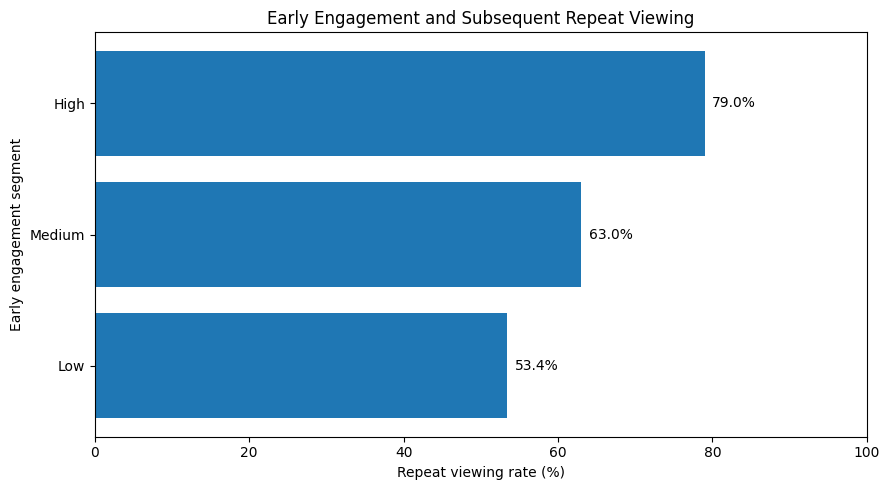

In [21]:
import matplotlib.pyplot as plt

# Use the follow-up analysis already calculated
plot_data = summary.sort_values("repeat_viewing_rate_pct")

plt.figure(figsize=(9, 5))
plt.barh(
    plot_data["engagement_segment"].astype(str),
    plot_data["repeat_viewing_rate_pct"]
)

plt.xlabel("Repeat viewing rate (%)")
plt.ylabel("Early engagement segment")
plt.title("Early Engagement and Subsequent Repeat Viewing")
plt.xlim(0, 100)

for i, value in enumerate(plot_data["repeat_viewing_rate_pct"]):
    plt.text(value + 1, i, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()

In [22]:
plan_analysis = subscriber_analysis.groupby(
    "subscription_plan", observed=True
).agg(
    subscribers=("subscriber_id", "count"),
    avg_watch_time_mins=("total_watch_time_mins", "mean"),
    avg_sessions=("total_sessions", "mean")
).reset_index()

display(plan_analysis.round(2))

,subscription_plan,subscribers,avg_watch_time_mins,avg_sessions
0,Basic,2771,1077.54,15.16
1,Mobile,3146,1065.69,14.87
2,Premium,1550,1084.81,15.22
3,Standard,2533,1054.93,14.86


In [23]:
plan_followup = followup.reset_index().merge(
    subscriber_analysis[
        ["subscriber_id", "subscription_plan"]
    ],
    on="subscriber_id",
    how="left"
)

plan_summary = plan_followup.groupby(
    "subscription_plan", observed=True
).agg(
    eligible_subscribers=("subscriber_id", "count"),
    repeat_viewers=("returned_days_30_to_59", "sum"),
    repeat_viewing_rate=("returned_days_30_to_59", "mean")
).reset_index()

plan_summary["repeat_viewing_rate_pct"] = (
    plan_summary["repeat_viewing_rate"] * 100
)

display(plan_summary.round(2))

,subscription_plan,eligible_subscribers,repeat_viewers,repeat_viewing_rate,repeat_viewing_rate_pct
0,Basic,2759,1817,0.66,65.86
1,Mobile,3138,2047,0.65,65.23
2,Premium,1546,985,0.64,63.71
3,Standard,2525,1644,0.65,65.11


In [24]:
device_analysis = subscriber_analysis.groupby(
    "primary_device", observed=True
).agg(
    subscribers=("subscriber_id", "count"),
    avg_watch_time_mins=("total_watch_time_mins", "mean"),
    avg_sessions=("total_sessions", "mean")
).reset_index()

display(
    device_analysis.sort_values(
        "avg_watch_time_mins", ascending=False
    ).round(2)
)

,primary_device,subscribers,avg_watch_time_mins,avg_sessions
2,Smart TV,2833,1074.70,15.03
0,Laptop,1808,1070.72,15.06
1,Mobile,4761,1066.15,14.96
3,Tablet,598,1062.99,14.98


In [25]:
device_followup = followup.reset_index().merge(
    subscriber_analysis[
        ["subscriber_id", "primary_device"]
    ],
    on="subscriber_id",
    how="left"
)

device_summary = device_followup.groupby(
    "primary_device", observed=True
).agg(
    eligible_subscribers=("subscriber_id", "count"),
    repeat_viewers=("returned_days_30_to_59", "sum"),
    repeat_viewing_rate=("returned_days_30_to_59", "mean")
).reset_index()

device_summary["repeat_viewing_rate_pct"] = (
    device_summary["repeat_viewing_rate"] * 100
)

display(device_summary.round(2))

,primary_device,eligible_subscribers,repeat_viewers,repeat_viewing_rate,repeat_viewing_rate_pct
0,Laptop,1800,1181,0.66,65.61
1,Mobile,4744,3058,0.64,64.46
2,Smart TV,2827,1855,0.66,65.62
3,Tablet,597,399,0.67,66.83


## 7. Statistical Testing

In [26]:
from scipy.stats import chi2_contingency

# Compare only the low and high early-engagement groups
comparison = followup[
    followup["engagement_segment"].isin(["Low", "High"])
].copy()

contingency_table = pd.crosstab(
    comparison["engagement_segment"],
    comparison["returned_days_30_to_59"]
)

display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.6g}")

returned_days_30_to_59,False,True
engagement_segment,,
Low,1548,1775
High,698,2625


Chi-square statistic: 484.74
P-value: 1.98273e-107


## 7. Statistical Testing

In [28]:
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / n)

print(f"Cramer's V: {cramers_v:.3f}")

Cramer's V: 0.270


## 8. Key Findings

### 1. Early Engagement and Repeat Viewing

Subscribers in the high early-engagement segment had a repeat-viewing rate of **78.99%**, compared with **53.42%** in the low-engagement segment. This represents a difference of **25.57 percentage points**.

A chi-square test indicated an association between engagement segment and subsequent repeat viewing (χ² = 484.74, p < 0.001; Cramér's V = 0.270).

### 2. Content Genre Performance

Thriller recorded the highest average completion rate at **80.01%**, while Documentary had the lowest at **74.44%**. Drama recorded the largest viewing volume, with **37,427 sessions**.

Completion rate and viewing volume measure different aspects of content performance and should not be treated as interchangeable.

### 3. Acquisition Channel Comparison

Social Media had the highest average cumulative watch time per subscriber at approximately **1,085 minutes**. However, differences across acquisition channels were small, and viewing activity alone cannot establish which channel delivers the best return on investment.

### 4. Subscription Plan and Device Comparison

Repeat-viewing rates varied only modestly across subscription plans and primary devices. Additional evidence would be required to determine whether these differences are meaningful for business decisions.

## 9. Business Recommendations

1. **Investigate early engagement:** Evaluate onboarding, content discovery and personalised recommendations as potential ways to encourage repeat viewing. Test interventions before claiming they improve retention.
2. **Evaluate content on multiple metrics:** Consider completion rate, viewing volume, repeat viewing and content costs together when assessing content performance.
3. **Measure acquisition efficiency:** Combine viewing behaviour with acquisition costs, subscription revenue and longer-term subscriber outcomes before reallocating marketing budgets.
4. **Monitor device-specific experience:** Investigate usability and playback issues across devices rather than assuming that device type explains differences in repeat viewing.

## 10. Limitations

- The dataset is simulated and does not represent real OTT customers.
- Repeat viewing is a behavioural proxy, not confirmed subscription retention or churn.
- The analysis is observational and cannot establish causality.
- Genre completion differences may reflect content length, selection effects or other factors not examined here.
- Statistical significance within simulated data does not establish real-world business significance.

## 11. Conclusion

This project demonstrates a reproducible approach to subscriber-level aggregation, engagement segmentation, repeat-viewing analysis, content-performance comparison and statistical testing. The clearest pattern in the generated dataset is the association between early viewing engagement and subsequent repeat viewing. Further analysis using real subscriber and subscription-status data would be necessary to validate these insights for an actual OTT business.